# 01 · Análisis exploratorio de datos

Dataset unificado **TMDb 5000** (metadatos) + **MovieLens ml-latest-small** (valoraciones). Generado con `python scripts/build_dataset.py`.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from queveo import config as C
from queveo.data import load_catalog, load_ratings
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
IMG = C.ROOT / 'docs' / 'img'; IMG.mkdir(parents=True, exist_ok=True)
cat, rat = load_catalog(), load_ratings()
print(cat.shape, rat.shape)

(4137, 44) (66709, 4)


## 1. Calidad del dato
Nulos tras la limpieza y valores imputados.

In [2]:
print('Nulos por columna (solo >0):')
print(cat.isna().sum()[lambda s: s > 0])
print('Duraciones imputadas por mediana de género:', int(cat.runtime_imputed.sum()))
print('Películas con valoraciones MovieLens:', int((cat.ml_n > 0).sum()))
cat[['year', 'runtime', 'vote_average', 'vote_count', 'popularity']].describe().round(2)

Nulos por columna (solo >0):
ml_mean    850
dtype: int64
Duraciones imputadas por mediana de género: 1
Películas con valoraciones MovieLens: 3287


,year,runtime,vote_average,vote_count,popularity
count,4137.00,4137.00,4137.00,4137.00,4137.00
mean,2002.35,109.07,6.26,800.07,24.75
std,12.19,20.67,0.86,1297.15,33.14
min,1916.00,25.00,1.90,20.00,0.01
25%,1999.00,95.00,5.70,108.00,7.65
50%,2005.00,105.00,6.30,325.00,16.18
75%,2010.00,119.00,6.90,882.00,31.79
max,2016.00,338.00,8.50,13752.00,875.58


## 2. Distribución de géneros

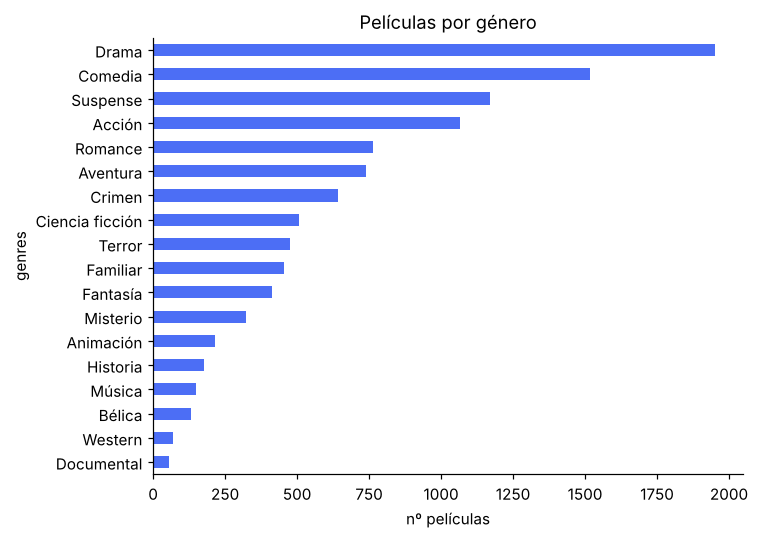

In [3]:
g = cat.explode('genres')['genres'].map(C.GENRES_ES).value_counts()
ax = g.sort_values().plot.barh(figsize=(7, 5), color='#4C6EF5')
ax.set_title('Películas por género'); ax.set_xlabel('nº películas')
plt.tight_layout(); plt.savefig(IMG / 'eda_generos.png'); plt.show()

## 3. Duración y época
La duración es clave porque la app filtra por *tiempo disponible*.

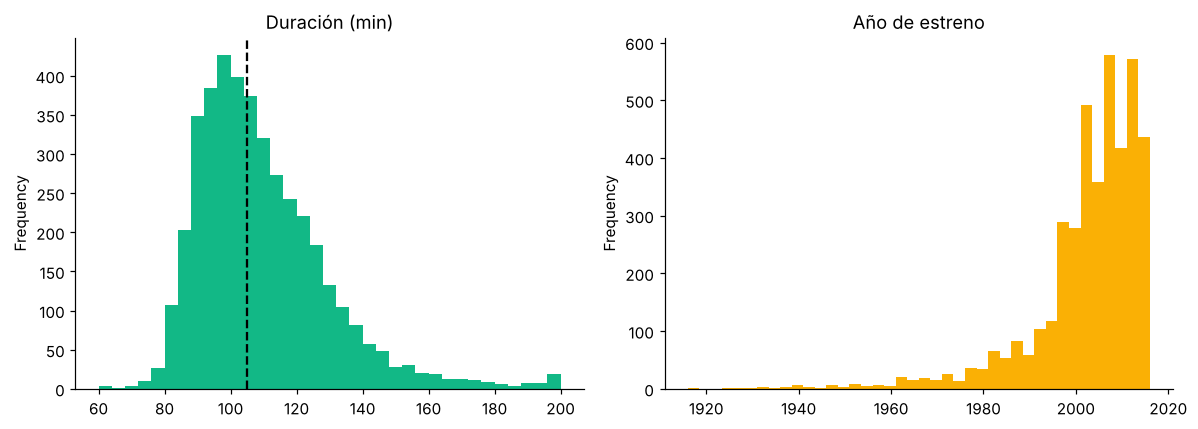

% películas <= 90 min: 14.7


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
cat.runtime.clip(60, 200).plot.hist(bins=35, ax=axs[0], color='#12B886')
axs[0].set_title('Duración (min)'); axs[0].axvline(cat.runtime.median(), ls='--', c='k')
cat.year.plot.hist(bins=40, ax=axs[1], color='#FAB005'); axs[1].set_title('Año de estreno')
plt.tight_layout(); plt.savefig(IMG / 'eda_duracion_anio.png'); plt.show()
print('% películas <= 90 min:', round((cat.runtime <= 90).mean() * 100, 1))

## 4. Valoraciones de usuarios (MovieLens)

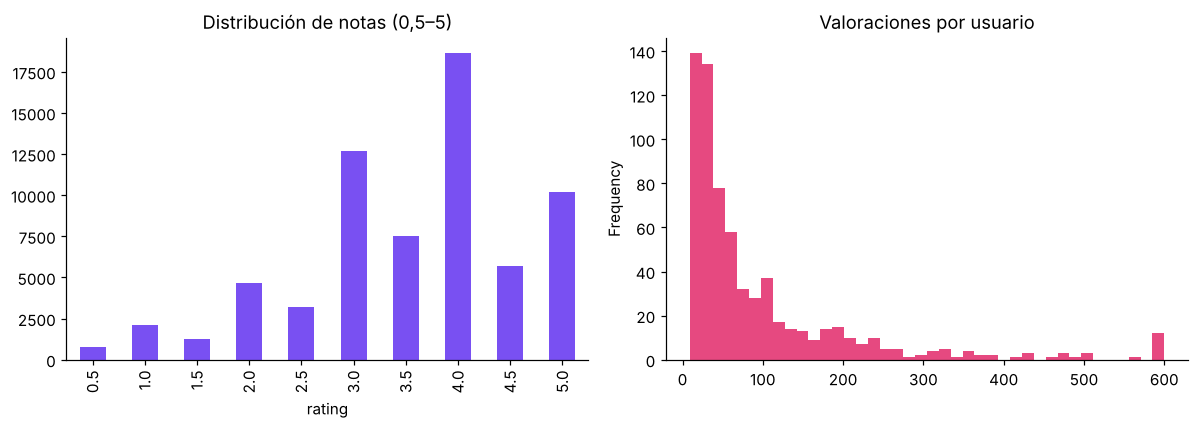

Media global: 3.56 · Densidad de la matriz: 3.02%


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
rat.rating.value_counts().sort_index().plot.bar(ax=axs[0], color='#7950F2')
axs[0].set_title('Distribución de notas (0,5–5)')
rat.groupby('user_id').size().clip(upper=600).plot.hist(bins=40, ax=axs[1], color='#E64980')
axs[1].set_title('Valoraciones por usuario'); plt.tight_layout()
plt.savefig(IMG / 'eda_ratings.png'); plt.show()
dens = len(rat) / (rat.user_id.nunique() * rat.tmdb_id.nunique())
print(f'Media global: {rat.rating.mean():.2f} · Densidad de la matriz: {dens:.2%}')

## 5. ¿Qué explica la satisfacción?
Relación entre la nota de MovieLens y variables de contenido.

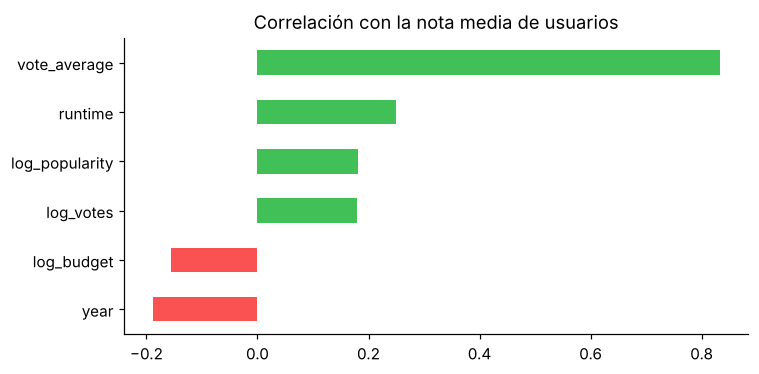

year             -0.189
log_budget       -0.157
log_votes         0.180
log_popularity    0.180
runtime           0.250
vote_average      0.832
Name: ml_mean, dtype: float64

In [6]:
m = cat[cat.ml_n >= 10]
cols = ['ml_mean', 'vote_average', 'log_votes', 'log_popularity', 'runtime', 'year', 'log_budget']
corr = m[cols].corr()['ml_mean'].drop('ml_mean').sort_values()
ax = corr.plot.barh(color=['#FA5252' if v < 0 else '#40C057' for v in corr], figsize=(7, 3.5))
ax.set_title('Correlación con la nota media de usuarios'); plt.tight_layout()
plt.savefig(IMG / 'eda_correlaciones.png'); plt.show(); corr.round(3)

In [7]:
gm = (rat.merge(cat[['tmdb_id', 'genres']], on='tmdb_id').explode('genres')
        .groupby('genres').rating.agg(['mean', 'count']).sort_values('mean'))
gm.index = gm.index.map(C.GENRES_ES); gm.round(2)

,mean,count
genres,,
Terror,3.26,3877
Comedia,3.43,21718
Acción,3.45,20836
Fantasía,3.45,9119
Ciencia ficción,3.46,11916
Aventura,3.49,17472
Suspense,3.50,18700
Misterio,3.50,5745
Familiar,3.52,7606


## 6. Disponibilidad por plataforma (aproximada)

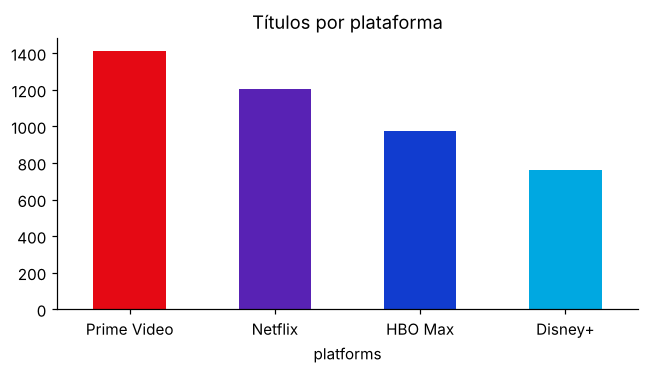

Sin plataforma: 1156


In [8]:
p = cat.explode('platforms')['platforms'].value_counts()
ax = p.plot.bar(color=['#E50914', '#5822B4', '#113CCF', '#00A8E1'], figsize=(6, 3.5), rot=0)
ax.set_title('Títulos por plataforma'); plt.tight_layout()
plt.savefig(IMG / 'eda_plataformas.png'); plt.show()
print('Sin plataforma:', (cat.platforms.str.len() == 0).sum())

## Conclusiones
* La `vote_average` de TMDb y el número de votos son los mejores predictores *a priori* de la satisfacción (r≈0,83 para la nota TMDb); la duración y la antigüedad se asocian positivamente (sesgo de supervivencia de los clásicos) y el presupuesto, negativamente (blockbusters).
* La matriz usuario-película es muy dispersa (~3 %), por lo que un filtrado colaborativo puro no basta: se justifica un **modelo híbrido** que combine perfil del usuario y contenido.
* Las preferencias por género difieren entre usuarios, lo que permite aprender la interacción *afinidad del usuario × géneros de la película*, que es lo que la app simula con el estado de ánimo.